# Entrega 3

**Proyecto:** predicción de resultados de fútbol europeo (victoria local / empate / victoria visitante) — Andes Sports Analytics.
**Fuente:** *European Soccer Database* (SQLite).

Esta entrega desarrolla tres modelos de clasificación multiclase sobre los mismos datos:

| Modelo | Tipo exigido |
|---|---|
| Regresión logística | modelo lineal |
| Árbol de decisión | árbol de decisión |
| Random forest | modelo de ensamble |

Para que los tres modelos sean **comparables**, todo lo que no es propio de cada modelo vive en la **Parte A** de este notebook y es común a los tres: la lectura y limpieza de los datos, la matriz de características, la partición de entrenamiento y prueba, el esquema de validación cruzada, la métrica de sintonización y las funciones de reporte. Cada modelo se desarrolla después en su propia sección, sin modificar nada de la Parte A.

# Parte A — Base común a los tres modelos

> **Regla del equipo:** las celdas de esta parte no se modifican al desarrollar cada modelo. Si alguien necesita cambiar algo de aquí (una variable, la limpieza, la métrica), se acuerda entre los tres y se cambia para todos, porque cualquier cambio en las filas de `X` cambia la partición.

## A.1 Configuración inicial

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from sqlalchemy import create_engine

warnings.filterwarnings('ignore')

# semilla única para la partición, la validación cruzada, la búsqueda aleatoria y los estimadores
SEED = 1

# la base se busca en las rutas habituales: Colab, la carpeta datos/, la carpeta database.sqlite/
# del proyecto, junto al notebook o en la carpeta padre
rutas = [Path("/content/database.sqlite"), Path("datos/database.sqlite"),
         Path("database.sqlite/database.sqlite"), Path("database.sqlite"),
         Path("../database.sqlite")]
file_path = next((p for p in rutas if p.is_file()), rutas[0])
print("Base de datos:", file_path.resolve())
engine = create_engine(f'sqlite:///{file_path}')

Base de datos: C:\Users\USER\ap-2026-1-61\proyecto_aula\database.sqlite\database.sqlite


## A.2 Lectura y limpieza de los datos

Se reproducen exactamente las decisiones de limpieza justificadas en la Entrega 2 (puntos 1.f a 1.h). Solo se cargan las tres tablas de las que salen la variable objetivo y las características del modelo: `Match`, `Team_Attributes` y `Player_Attributes`. `Player`, `Team`, `League` y `Country` se analizaron en la Entrega 2, pero no aportan columnas al modelo.

In [2]:
df_match = pd.read_sql("SELECT * FROM Match", engine)
df_team_attr = pd.read_sql("SELECT * FROM Team_Attributes", engine)
df_player_attr = pd.read_sql("SELECT * FROM Player_Attributes", engine)

for nombre, df in [('Match', df_match), ('Team_Attributes', df_team_attr),
                   ('Player_Attributes', df_player_attr)]:
    print(f"{nombre:<18} {df.shape[0]:>7,} filas | {df.shape[1]:>3} columnas")

Match               25,979 filas | 115 columnas
Team_Attributes      1,458 filas |  25 columnas
Player_Attributes  183,978 filas |  42 columnas


In [3]:
# corrección de tipos: las fechas llegan como texto
df_match['date'] = pd.to_datetime(df_match['date'])
df_team_attr['date'] = pd.to_datetime(df_team_attr['date'])
df_player_attr['date'] = pd.to_datetime(df_player_attr['date'])

In [4]:
# Player_Attributes
# 1) eliminamos la fila-fantasma de cada par duplicado (player_api_id, date): conservamos la fila con no nulo
antes = len(df_player_attr)
df_player_attr_clean = (
    df_player_attr
    .sort_values('overall_rating', na_position='last')
    .drop_duplicates(subset=['player_api_id', 'date'], keep='first')
    .drop(columns=['id', 'player_fifa_api_id'])
)
print(f"Filas: {antes} -> {len(df_player_attr_clean)} (se eliminaron {antes - len(df_player_attr_clean)} filas-fantasma)")

# 2) limpiar categorías inválidas de las work rate: cualquier valor fuera de
#    low, medium, high pasa a nulo
validas = {'low', 'medium', 'high'}
for col in ['attacking_work_rate', 'defensive_work_rate']:
    invalidas = ~df_player_attr_clean[col].isin(validas)
    df_player_attr_clean.loc[invalidas, col] = np.nan

Filas: 183978 -> 183142 (se eliminaron 836 filas-fantasma)


In [5]:
# Team_Attributes
# 1) eliminamos la fila exactamente duplicada
antes = len(df_team_attr)
df_team_attr_clean = df_team_attr.drop_duplicates(subset=['team_api_id', 'date'], keep='first')
print(f"Filas: {antes} -> {len(df_team_attr_clean)}")

# 2) se prioriza buildUpPlayDribblingClass (completa) sobre buildUpPlayDribbling (más del 50% nulo)
df_team_attr_clean = df_team_attr_clean.drop(columns=['id', 'team_fifa_api_id', 'buildUpPlayDribbling'])

Filas: 1458 -> 1457


In [6]:
# Match
# 1) construimos la variable objetivo ANTES de retirar los goles
condiciones = [
    df_match['home_team_goal'] > df_match['away_team_goal'],
    df_match['home_team_goal'] == df_match['away_team_goal'],
    df_match['home_team_goal'] < df_match['away_team_goal'],
]
df_match['resultado'] = np.select(condiciones, ['victoria_local', 'empate', 'victoria_visitante'], default='')

# 2) descartamos columnas de fuga de datos y de eventos en partido; las cuotas se guardan aparte
#    como benchmark de mercado, no entran al modelo
cols_eventos = ['goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']
cols_cuotas = [c for c in df_match.columns if len(c) <= 4 and c[-1] in 'HDA' and c not in ('id',)]

df_cuotas = df_match[['match_api_id'] + cols_cuotas].copy()

df_match_clean = df_match.drop(columns=(
    ['id', 'home_team_goal', 'away_team_goal'] + cols_eventos + cols_cuotas
))
df_match_clean.shape

(25979, 78)

## A.3 Dataframe de modelado

Una fila por partido, con la variable objetivo y solo información disponible antes del pitazo inicial (Entrega 2, punto 1.i): el perfil táctico más reciente de cada club y la valoración media de los once titulares de cada lado.

In [7]:
# Dataframe base: una fila por partido, con la variable objetivo
df_modelo = df_match_clean[['match_api_id', 'league_id', 'season', 'stage',
                            'home_team_api_id', 'away_team_api_id', 'resultado']]

# Bloque 1: perfil táctico de cada equipo (la ficha más reciente de cada club)
perfil_equipo = (df_team_attr_clean
                 .sort_values('date')
                 .drop_duplicates(subset=['team_api_id'], keep='last')
                 .drop(columns=['date']))

perfil_local = perfil_equipo.copy()
perfil_local.columns = ['local_' + c for c in perfil_equipo.columns]

perfil_visitante = perfil_equipo.copy()
perfil_visitante.columns = ['visitante_' + c for c in perfil_equipo.columns]

df_modelo = df_modelo.merge(perfil_local, left_on='home_team_api_id',
                            right_on='local_team_api_id', how='left')
df_modelo = df_modelo.merge(perfil_visitante, left_on='away_team_api_id',
                            right_on='visitante_team_api_id', how='left')
df_modelo = df_modelo.drop(columns=['local_team_api_id', 'visitante_team_api_id'])
print("Dimensiones tras el bloque táctico:", df_modelo.shape)

Dimensiones tras el bloque táctico: (25979, 47)


In [8]:
# Bloque 2: calidad de la plantilla alineada (valoración media histórica de cada jugador)
rating_jugador = (df_player_attr_clean
                  .groupby('player_api_id')[['overall_rating', 'potential']]
                  .mean()
                  .reset_index())

# las columnas de alineación de Match guardan el id del jugador como decimal (porque tienen nulos)
rating_jugador['player_api_id'] = rating_jugador['player_api_id'].astype('float64')

cols_home = [f'home_player_{i}' for i in range(1, 12)]
cols_away = [f'away_player_{i}' for i in range(1, 12)]


def rating_de_la_alineacion(cols_titulares, prefijo):
    tabla = df_match_clean[['match_api_id']]
    for i, col in enumerate(cols_titulares, start=1):
        titular = df_match_clean[['match_api_id', col]].merge(
            rating_jugador, left_on=col, right_on='player_api_id', how='left')
        titular = titular[['match_api_id', 'overall_rating', 'potential']]
        titular.columns = ['match_api_id', f'rating_{i}', f'potencial_{i}']
        tabla = tabla.merge(titular, on='match_api_id', how='left')

    resumen = tabla[['match_api_id']].copy()
    resumen[prefijo + '_rating_medio'] = tabla[[f'rating_{i}' for i in range(1, 12)]].mean(axis=1)
    resumen[prefijo + '_potencial_medio'] = tabla[[f'potencial_{i}' for i in range(1, 12)]].mean(axis=1)
    return resumen


df_modelo = df_modelo.merge(rating_de_la_alineacion(cols_home, 'local'),
                            on='match_api_id', how='left')
df_modelo = df_modelo.merge(rating_de_la_alineacion(cols_away, 'visitante'),
                            on='match_api_id', how='left')
print("Dimensiones tras el bloque de plantilla:", df_modelo.shape)

Dimensiones tras el bloque de plantilla: (25979, 51)


In [9]:
# Gestión de nulos: se eliminan los partidos sin perfil táctico o sin alineación registrada
antes = df_modelo.shape[0]
df_modelo = df_modelo.dropna()
df_modelo = df_modelo.reset_index(drop=True)
print(f"Partidos utilizables: {antes} -> {df_modelo.shape[0]}")
print("Nulos que quedan en el dataframe:", df_modelo.isnull().sum().sum())

Partidos utilizables: 25979 -> 24967
Nulos que quedan en el dataframe: 0


## A.4 Matriz de características y vector objetivo

Mismas 30 variables de la Entrega 2 (punto 4.b): 21 numéricas, 2 ordinales y 7 nominales. Se descartan las llaves, la temporada y las versiones `*Class` que solo discretizan una variable numérica ya presente.

In [10]:
X = df_modelo.drop(
    ['match_api_id', 'season', 'resultado', 'home_team_api_id', 'away_team_api_id'],
    axis=1
    )
y = df_modelo['resultado']

clases_redundantes = [f'{lado}_{c}' for lado in ('local', 'visitante') for c in
                      ['buildUpPlaySpeedClass', 'buildUpPlayPassingClass',
                       'chanceCreationPassingClass', 'chanceCreationCrossingClass',
                       'chanceCreationShootingClass', 'defencePressureClass',
                       'defenceAggressionClass', 'defenceTeamWidthClass']]
X = X.drop(clases_redundantes, axis=1)

cat_ordinales = [f'{lado}_buildUpPlayDribblingClass' for lado in ('local', 'visitante')]
cat_nominales = [f'{lado}_{c}' for lado in ('local', 'visitante') for c in
                 ['buildUpPlayPositioningClass', 'chanceCreationPositioningClass',
                  'defenceDefenderLineClass']] + ['league_id']

X['league_id'] = X['league_id'].astype(str)   # es un identificador de categoría, no una magnitud
num_features = [c for c in X.columns if c not in cat_ordinales + cat_nominales]

print(f"X: {X.shape} -> {len(num_features)} numéricas, "
      f"{len(cat_ordinales)} ordinales, {len(cat_nominales)} nominales")
print("\nDistribución de la variable objetivo:")
print(y.value_counts(normalize=True).round(3))

X: (24967, 30) -> 21 numéricas, 2 ordinales, 7 nominales

Distribución de la variable objetivo:
resultado
victoria_local        0.458
victoria_visitante    0.288
empate                0.254
Name: proportion, dtype: float64


## A.5 Partición en entrenamiento y prueba

Se usa **la misma partición de la Entrega 2**: `train_test_split` 80/20 con `random_state=1`. La celda siguiente comprueba que se obtienen los mismos tamaños (19.973 y 4.994 partidos) y calcula una huella de los índices de prueba. Si a alguien le sale una huella distinta, no está usando la misma partición.

**Limitación que se reconoce:** la partición es aleatoria, no temporal. Se mezclan partidos de una misma temporada entre entrenamiento y prueba, así que las métricas de prueba miden la capacidad de generalizar a partidos *no vistos* de las mismas temporadas, no a temporadas futuras.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, train_size=0.8)

print(f'Tamaño del conjunto de entrenamiento es: {X_train.shape}')
print(f'Tamaño del conjunto de prueba es: {X_test.shape}')
assert X_train.shape == (19973, 30) and X_test.shape == (4994, 30), \
    "La partición no coincide con la de la Entrega 2"

# huella de la partición: debe dar lo mismo en el computador de los tres integrantes
print("Huella de la partición:", pd.util.hash_pandas_object(X_test.index.to_series()).sum())

display(pd.DataFrame({'entrenamiento': y_train.value_counts(normalize=True),
                      'prueba': y_test.value_counts(normalize=True)}).round(3))

Tamaño del conjunto de entrenamiento es: (19973, 30)
Tamaño del conjunto de prueba es: (4994, 30)
Huella de la partición: 16549817950499170654


,entrenamiento,prueba
resultado,,
victoria_local,0.457,0.462
victoria_visitante,0.289,0.286
empate,0.254,0.253


## A.6 Preprocesamiento

Las codificaciones son las mismas para los tres modelos: `OrdinalEncoder` con orden explícito para `buildUpPlayDribblingClass` y `OneHotEncoder` para las nominales. Lo único que cambia es el escalamiento de las numéricas:

| Preprocesador | Modelo | Numéricas |
|---|---|---|
| `preprocessor_lineal` | regresión logística | `StandardScaler` o `RobustScaler` según el diagnóstico de la Entrega 2 (punto 4.d), calculado solo con `X_train` |
| `preprocessor_arboles` | árbol de decisión y random forest | sin transformar (`passthrough`): los árboles dividen por umbrales y no son sensibles a la escala |

Los dos preprocesadores se usan **dentro** de un `Pipeline` junto al estimador, de modo que todo se ajusta solo con los datos de entrenamiento de cada pliegue de la validación cruzada (sin fuga de datos).

In [12]:
# reparto de las numéricas entre los dos escaladores, con el criterio de la Entrega 2 y solo sobre X_train
def atipicos_iqr(serie):
    Q1, Q3 = serie.quantile(0.25), serie.quantile(0.75)
    IQR = Q3 - Q1
    return ((serie < Q1 - 1.5 * IQR) | (serie > Q3 + 1.5 * IQR)).mean() * 100


diagnostico = pd.DataFrame({
    'asimetria': X_train[num_features].skew(),
    '%_atipicos': X_train[num_features].apply(atipicos_iqr),
})
diagnostico['criterio'] = ['RobustScaler' if abs(a) > 0.5 or p > 1 else 'StandardScaler'
                           for a, p in zip(diagnostico['asimetria'], diagnostico['%_atipicos'])]

num_estandar = diagnostico[diagnostico['criterio'] == 'StandardScaler'].index.tolist()
num_robusto = diagnostico[diagnostico['criterio'] == 'RobustScaler'].index.tolist()
print(f"StandardScaler ({len(num_estandar)}) | RobustScaler ({len(num_robusto)}): {num_robusto}")

StandardScaler (17) | RobustScaler (4): ['local_chanceCreationShooting', 'local_defenceTeamWidth', 'visitante_chanceCreationShooting', 'visitante_defenceTeamWidth']


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler

orden = ['Little', 'Normal', 'Lots']   # orden justificado en la Entrega 2, punto 2.a

preprocessor_lineal = ColumnTransformer(transformers=[
    ('num_estandar', StandardScaler(), num_estandar),
    ('num_robusto', RobustScaler(), num_robusto),
    ('ordinal', OrdinalEncoder(categories=[orden] * len(cat_ordinales), dtype='int'), cat_ordinales),
    ('nominal', OneHotEncoder(sparse_output=False, drop='if_binary'), cat_nominales)
    ], remainder='drop')

preprocessor_arboles = ColumnTransformer(transformers=[
    ('num', 'passthrough', num_features),
    ('ordinal', OrdinalEncoder(categories=[orden] * len(cat_ordinales), dtype='int'), cat_ordinales),
    ('nominal', OneHotEncoder(sparse_output=False, drop='if_binary'), cat_nominales)
    ], remainder='drop')

preprocessor_lineal

,transformers,"[('num_estandar', ...), ('num_robusto', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


## A.7 Protocolo de sintonización y evaluación

Los tres modelos se sintonizan con **la misma técnica**:

- **Búsqueda:** `RandomizedSearchCV` con `n_iter=N_ITER` combinaciones y `random_state=SEED`, como en los cuadernos 16, 18 y 21 del curso.
- **Validación cruzada:** `StratifiedKFold` de 5 pliegues, el mismo objeto `cv` para todos. Al no barajar, los pliegues son idénticos para los tres modelos.
- **Métrica de sintonización:** `f1_macro` (la del cuaderno 18 para clasificación multiclase). Pondera igual las tres clases, así que castiga a un modelo que nunca predice el empate, el problema detectado en la Entrega 2. La exactitud sola lo esconde, porque predecir siempre victoria local ya da 46 %.
- **Métricas reportadas:** `f1_macro`, exactitud y `log_loss` en **validación** (media de la validación cruzada del mejor modelo), **entrenamiento** y **prueba**. El `log_loss` evalúa las probabilidades, que son el producto del proyecto.
- **Importancia de las características:** además de la propia de cada modelo (coeficientes o `feature_importances_`), se calcula la **importancia por permutación** sobre el conjunto de prueba con la misma función para los tres. Está medida sobre las 30 variables originales y en la misma escala, así que es la que permite comparar los modelos entre sí.

Cada estimador se crea con `random_state=SEED`.

In [14]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (get_scorer, classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

N_ITER = 50
cv = StratifiedKFold(n_splits=5)
SCORING = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy', 'neg_log_loss': 'neg_log_loss'}
REFIT = 'f1_macro'

# aquí cada modelo deja sus métricas para la comparación final
resultados = {}

In [15]:
def reportar_modelo(tuner, nombre):
    # Reporta y guarda las métricas de validación, entrenamiento y prueba de un RandomizedSearchCV ya
    # ajustado con scoring=SCORING y refit=REFIT. El log_loss se reporta en positivo (menor es mejor).
    modelo = tuner.best_estimator_
    cv_res = tuner.cv_results_
    filas = {}
    for metrica, scorer_name in SCORING.items():
        scorer = get_scorer(scorer_name)
        signo = -1 if metrica.startswith('neg_') else 1
        filas[metrica.replace('neg_', '')] = {
            'validacion': signo * cv_res[f'mean_test_{metrica}'][tuner.best_index_],
            'entrenamiento': signo * scorer(modelo, X_train, y_train),
            'prueba': signo * scorer(modelo, X_test, y_test),
        }
    tabla = pd.DataFrame(filas).T
    resultados[nombre] = tabla

    print(f"===== {nombre} =====")
    print("Hiperparámetros sintonizados:")
    for parametro, valor in tuner.best_params_.items():
        print(f"  {parametro}: {valor}")
    display(tabla.round(4))

    print("Reporte de clasificación en el conjunto de prueba:")
    print(classification_report(y_test, modelo.predict(X_test)))
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, xticks_rotation=20)
    return tabla


def importancia_permutacion(tuner, nombre, n_repeats=10):
    # Importancia por permutación sobre las 30 variables originales de X_test, con la métrica de
    # sintonización: cuánto cae el f1_macro al desordenar cada variable.
    imp = permutation_importance(tuner.best_estimator_, X_test, y_test, scoring=REFIT,
                                 n_repeats=n_repeats, random_state=SEED, n_jobs=-1)
    return (pd.DataFrame({'importancia_media': imp.importances_mean,
                          'desviacion': imp.importances_std}, index=X_test.columns)
            .sort_values('importancia_media', ascending=False)
            .rename_axis(nombre))

### Plantilla que sigue cada modelo

```python
pipeline_x = Pipeline(steps=[
    ('preprocessor', preprocessor_lineal),   # o preprocessor_arboles
    ('model', Estimador(random_state=SEED))
])

tuner_x = RandomizedSearchCV(pipeline_x, param_distributions=dist, n_iter=N_ITER, cv=cv,
                             scoring=SCORING, refit=REFIT, random_state=SEED, n_jobs=-1)
tuner_x.fit(X_train, y_train)

reportar_modelo(tuner_x, 'Nombre del modelo')
importancia_permutacion(tuner_x, 'Nombre del modelo')
```

Además, cada modelo reporta su tabla propia de pesos o importancias (`coef_` en la regresión logística, `feature_importances_` en los árboles) con los nombres de `get_feature_names_out()` del preprocesador.

# Parte B — Modelos

## B.1 Modelo lineal: regresión logística

La regresión logística es el modelo lineal de clasificación visto en clase y la línea base del proyecto (objetivo específico 2 de la Entrega 1). Con tres clases ajusta la versión **multinomial** (softmax): aprende un vector de pesos por clase y entrega directamente la probabilidad de cada resultado, que es el producto que el proyecto quiere ofrecer.

### B.1.1 Preprocesamiento y pipeline

Se usa `preprocessor_lineal`. Un modelo lineal regularizado sí necesita las numéricas en una escala comparable: la penalización actúa sobre el tamaño de los coeficientes, y una variable medida en una escala grande quedaría penalizada de forma distinta a otra en una escala pequeña. Por eso las numéricas se escalan (`StandardScaler` o `RobustScaler` según el diagnóstico de A.6), las ordinales se codifican con su orden y las nominales con one-hot. Todo va dentro del `Pipeline`, así que en cada pliegue de la validación cruzada el escalamiento se aprende solo con los datos de entrenamiento de ese pliegue.

El estimador se configura como en los cuadernos 15 y 18 del curso: `solver='saga'`, que es el que admite las tres penalizaciones, `penalty='elasticnet'` y `max_iter=10000` para que converja con cualquier valor de `C`.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_lineal),
    ('model', LogisticRegression(solver='saga', penalty='elasticnet', max_iter=10000,
                                 random_state=SEED))
    ])

pipeline_lr

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num_estandar', ...), ('num_robusto', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### B.1.2 Hiperparámetros y espacios de búsqueda

| Hiperparámetro | Espacio de búsqueda | Por qué |
|---|---|---|
| `C` | `loguniform(1e-4, 1e4)` | es el inverso de la fuerza de regularización. El espacio va desde una penalización muy fuerte (casi todos los coeficientes en cero, modelo subajustado) hasta prácticamente sin penalización. Se muestrea en escala logarítmica porque lo que importa es el orden de magnitud, igual que en el cuaderno 18 |
| `l1_ratio` | `uniform(0, 1)` | mezcla de las dos penalizaciones de `elasticnet`: 0 es L2 pura (encoge todos los coeficientes) y 1 es L1 pura (lleva a cero los que no aportan, una selección de variables). Se deja que la validación cruzada decida |
| `class_weight` | `[None, 'balanced']` | el empate es la clase menos frecuente (25 %) y en la Entrega 2 el modelo casi nunca lo predijo. Con `'balanced'` los errores en las clases minoritarias pesan más en la función de pérdida (cuaderno 17) |

Se evalúan `N_ITER = 50` combinaciones con validación cruzada de 5 pliegues (250 ajustes), siguiendo el protocolo común de A.7.

In [17]:
from scipy.stats import loguniform, uniform

dist_lr = {
    'model__C': loguniform(1e-4, 1e4),
    'model__l1_ratio': uniform(0, 1),
    'model__class_weight': [None, 'balanced']
    }

tuner_lr = RandomizedSearchCV(
    estimator=pipeline_lr,
    param_distributions=dist_lr,
    n_iter=N_ITER,
    cv=cv,
    scoring=SCORING,
    refit=REFIT,
    random_state=SEED,
    n_jobs=-1
    )

tuner_lr.fit(X_train, y_train)

,estimator,Pipeline(step...ver='saga'))])
,param_distributions,"{'model__C': <scipy.stats....001C51DF022D0>, 'model__class_weight': [None, 'balanced'], 'model__l1_ratio': <scipy.stats....001C52D85EF60>}"
,n_iter,50
,scoring,"{'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'neg_log_loss': 'neg_log_loss'}"
,n_jobs,-1
,refit,'f1_macro'
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,1
,error_score,nan


### B.1.3 Métricas de validación, entrenamiento y prueba

===== Regresión logística =====
Hiperparámetros sintonizados:
  model__C: 1165.32947050119
  model__class_weight: balanced
  model__l1_ratio: 0.6477493997733476


,validacion,entrenamiento,prueba
f1_macro,0.4614,0.4669,0.4613
accuracy,0.4895,0.4949,0.4904
log_loss,1.0089,1.0043,1.0058


Reporte de clasificación en el conjunto de prueba:
                    precision    recall  f1-score   support

            empate       0.28      0.27      0.27      1261
    victoria_local       0.63      0.56      0.59      2305
victoria_visitante       0.47      0.57      0.52      1428

          accuracy                           0.49      4994
         macro avg       0.46      0.47      0.46      4994
      weighted avg       0.50      0.49      0.49      4994



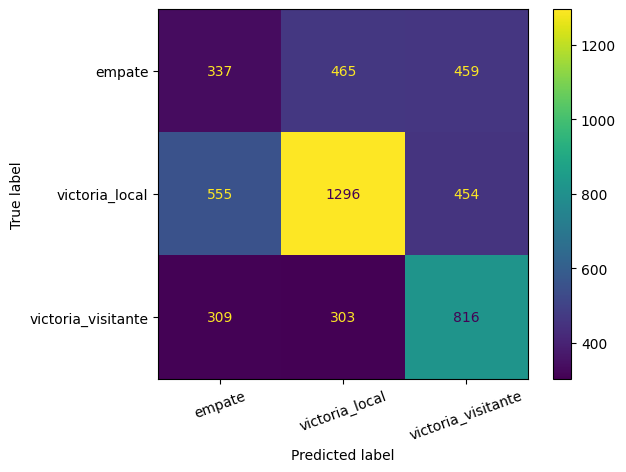

In [18]:
tabla_lr = reportar_modelo(tuner_lr, 'Regresión logística')

In [19]:
# las 10 mejores combinaciones de la búsqueda, para ver qué tan estable es la elección
busqueda_lr = (pd.DataFrame(tuner_lr.cv_results_)
               .sort_values('rank_test_f1_macro')
               [['param_model__C', 'param_model__l1_ratio', 'param_model__class_weight',
                 'mean_test_f1_macro', 'std_test_f1_macro', 'mean_test_accuracy']]
               .head(10))
busqueda_lr.round(4)

,param_model__C,param_model__l1_ratio,param_model__class_weight,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy
32,1165.3295,0.6477,balanced,0.4614,0.0042,0.4895
6,23.1068,0.4572,balanced,0.4613,0.0042,0.4895
27,218.3880,0.5866,balanced,0.4613,0.0042,0.4895
8,254.6575,0.8028,balanced,0.4613,0.0042,0.4895
46,110.5871,0.2086,balanced,0.4613,0.0042,0.4895
19,1686.4029,0.1300,balanced,0.4613,0.0042,0.4895
43,450.3402,0.9973,balanced,0.4613,0.0042,0.4895
3,22.8018,0.5388,balanced,0.4613,0.0042,0.4895
49,1.1981,0.8600,balanced,0.4612,0.0039,0.4896
17,0.3707,0.1032,balanced,0.4611,0.0040,0.4897


In [20]:
# mejor combinación de la búsqueda con y sin balanceo de clases (métricas de validación cruzada)
res_lr = pd.DataFrame(tuner_lr.cv_results_)
res_lr['class_weight'] = res_lr['param_model__class_weight'].astype(str)
mejor_por_peso = (res_lr.sort_values('rank_test_f1_macro')
                  .groupby('class_weight').head(1)
                  .set_index('class_weight')
                  [['param_model__C', 'param_model__l1_ratio',
                    'mean_test_f1_macro', 'mean_test_accuracy', 'mean_test_neg_log_loss']])
mejor_por_peso['mean_test_neg_log_loss'] *= -1
mejor_por_peso.rename(columns={'mean_test_neg_log_loss': 'mean_test_log_loss'}).round(4)

,param_model__C,param_model__l1_ratio,mean_test_f1_macro,mean_test_accuracy,mean_test_log_loss
class_weight,,,,,
balanced,1165.3295,0.6477,0.4614,0.4895,1.0089
None,1469.2299,0.8813,0.3923,0.5276,0.9784


**Lectura de las métricas y de la sintonización.**

- **Sin sobreajuste ni subajuste por regularización.** Validación, entrenamiento y prueba están a menos de 0,006 entre sí en las tres métricas, así que el modelo generaliza lo que aprende. El `C` elegido (≈ 1.165) es muy grande, es decir, una regularización casi nula: con ~20.000 partidos y 40 características no hay riesgo de memorizar, y la penalización no tiene nada que corregir. Por eso las 10 mejores combinaciones tienen el mismo `f1_macro` (0,461 ± 0,004) con valores de `C` entre 0,37 y 1.700 y `l1_ratio` entre 0,1 y 1: la superficie de búsqueda es plana en esos dos hiperparámetros.
- **El hiperparámetro que decide es `class_weight`.** Las 10 mejores combinaciones usan `'balanced'`. Con él el empate pasa de un recall de 0,01 en la Entrega 2 a 0,27, y el `f1_macro` sube de 0,39 a 0,46. Pero tiene un costo: la exactitud baja de 0,528 a 0,490 y el `log_loss` empeora de 0,978 a 1,009. El modelo ahora sí predice empates, a cambio de acertar menos victorias locales.
- **Frente a las líneas base.** La exactitud (0,490) supera la de predecir siempre victoria local (0,462), y el `log_loss` (1,006) es mejor que el de asignar a todos los partidos las frecuencias históricas de cada resultado (≈ 1,064). El margen es modesto: el resultado de un partido de fútbol tiene mucho azar, y con las variables disponibles el modelo lineal llega a un techo cercano al 50 %.

Este dilema afecta directamente al objetivo del proyecto: si lo que se quiere es **clasificar** también los empates, conviene `'balanced'`, que es lo que elige la métrica acordada (`f1_macro`). Si lo que se quiere son **probabilidades** para compararlas con las del mercado de apuestas, conviene `class_weight=None`, que da un mejor `log_loss`. Se retoma en la comparación de la Parte C.

### B.1.4 Pesos del modelo

Como el problema tiene tres clases, cada característica tiene **tres pesos**, uno por resultado (cuaderno 18). Un peso positivo en una clase significa que, al aumentar esa característica, aumenta la probabilidad de ese resultado frente a los otros dos. Como las numéricas están escaladas, los pesos de las numéricas se pueden comparar entre sí en tamaño.

In [21]:
modelo_lr = tuner_lr.best_estimator_
nombres_lr = modelo_lr.named_steps['preprocessor'].get_feature_names_out()

pesos_lr = pd.DataFrame(
    data=modelo_lr.named_steps['model'].coef_.T,
    index=nombres_lr,
    columns=modelo_lr.named_steps['model'].classes_
    )

# orden por el mayor peso en valor absoluto de cada característica, en cualquiera de las tres clases
orden_pesos = pesos_lr.abs().max(axis=1).sort_values(ascending=False).index
pesos_lr = pesos_lr.loc[orden_pesos]
pesos_lr.loc['intercept'] = modelo_lr.named_steps['model'].intercept_

print(f"Características: {len(nombres_lr)} | "
      f"con los tres pesos en cero (eliminadas por L1): {(pesos_lr.drop('intercept') == 0).all(axis=1).sum()}")
pesos_lr.round(4)

Características: 40 | con los tres pesos en cero (eliminadas por L1): 0


,empate,victoria_local,victoria_visitante
num_estandar__local_rating_medio,0.0342,0.7385,-0.7731
num_estandar__visitante_rating_medio,0.0104,-0.5649,0.5541
nominal__league_id_24558,-0.2012,0.1513,0.0496
nominal__league_id_19694,-0.1743,0.0158,0.1582
nominal__league_id_15722,-0.1689,0.1441,0.0244
nominal__league_id_4769,0.1678,-0.0771,-0.0903
num_estandar__local_potencial_medio,-0.1182,-0.0485,0.1671
nominal__league_id_1729,0.1566,-0.1508,-0.0055
nominal__league_id_1,-0.1402,0.1043,0.0356
nominal__league_id_10257,0.1136,-0.0520,-0.0613


**Lectura de los pesos.**

- **La calidad de las alineaciones domina.** Los dos pesos más grandes son los de `local_rating_medio` (+0,74 hacia victoria local, −0,77 hacia victoria visitante) y `visitante_rating_medio` (−0,56 y +0,55). Son simétricos: lo que suma a la victoria de un equipo resta a la del otro. Una desviación estándar más de valoración media de los once titulares es el efecto individual más fuerte del modelo.
- **El empate casi no depende de la calidad.** Los pesos de los dos ratings en la columna `empate` son prácticamente cero (0,03 y 0,01). El modelo no encuentra en los ratings una señal propia del empate; lo explica sobre todo con el intercepto y con la liga. Esto es coherente con que el empate sea la clase más difícil.
- **La liga es el segundo bloque.** Varias ligas tienen pesos de ±0,15 a ±0,20 en `empate`: Francia (`4769`, +0,17), Inglaterra (`1729`, +0,16) e Italia (`10257`, +0,11) empujan hacia el empate, mientras que Suiza (`24558`, −0,20), Escocia (`19694`, −0,17) y Polonia (`15722`, −0,17) lo alejan. Al estar codificadas con one-hot completo, estos pesos se leen como diferencias entre ligas, no como efectos absolutos.
- **`potencial_medio` corrige al rating.** Su peso es menor y de signo cruzado (por ejemplo, `local_potencial_medio` suma +0,17 a la victoria visitante). Rating y potencial están muy correlacionados, así que el modelo usa el potencial como un ajuste fino sobre el rating y no conviene interpretar su signo aislado.
- **Las variables tácticas pesan muy poco.** Ninguna supera 0,07 en valor absoluto. Aunque el `l1_ratio` elegido es 0,65, ningún coeficiente llega exactamente a cero porque `C` es tan grande que la penalización L1 casi no actúa.

### B.1.5 Importancia por permutación

Es la medida común a los tres modelos (A.7): cuánto cae el `f1_macro` en el conjunto de prueba al desordenar cada una de las 30 variables originales. A diferencia de los pesos, agrupa en una sola cifra las columnas one-hot de una misma variable (por ejemplo, las 11 de `league_id`).

In [22]:
importancia_lr = importancia_permutacion(tuner_lr, 'Regresión logística')
importancia_lr.round(4)

,importancia_media,desviacion
Regresión logística,,
local_rating_medio,0.1166,0.0057
visitante_rating_medio,0.0797,0.0068
local_potencial_medio,0.0098,0.0032
league_id,0.0021,0.0035
visitante_potencial_medio,0.0010,0.0020
visitante_buildUpPlayPassing,0.0009,0.0011
local_buildUpPlayPositioningClass,0.0007,0.0006
local_chanceCreationShooting,0.0005,0.0013
local_defencePressure,0.0002,0.0006


**Lectura de la importancia por permutación.** Confirma los pesos con más claridad: desordenar `local_rating_medio` hace caer el `f1_macro` en 0,117 y `visitante_rating_medio` en 0,080. La siguiente variable, `local_potencial_medio`, ya solo aporta 0,010, y todas las demás están por debajo de 0,003, dentro de su propia desviación. Varias variables tácticas tienen importancia **negativa**: desordenarlas no empeora el modelo, señal de que su aporte es ruido. En la práctica, la regresión logística es un modelo de **calidad de plantilla local contra calidad de plantilla visitante**, con un ajuste por liga. El perfil táctico del club, tal como se construyó (la ficha más reciente de cada equipo), no aporta capacidad predictiva lineal.

### B.1.6 Probabilidades estimadas

El modelo entrega la probabilidad de cada resultado (`predict_proba`). Si las probabilidades están bien calibradas, su promedio en el conjunto de prueba debe parecerse a la frecuencia real de cada resultado.

In [23]:
probs_lr = pd.DataFrame(modelo_lr.predict_proba(X_test),
                        columns=modelo_lr.named_steps['model'].classes_, index=X_test.index)

display(probs_lr.head().round(3))
display(pd.DataFrame({'probabilidad_media_estimada': probs_lr.mean(),
                      'frecuencia_real': y_test.value_counts(normalize=True)}).round(3))

,empate,victoria_local,victoria_visitante
17356,0.380,0.224,0.396
4792,0.368,0.212,0.420
8765,0.296,0.578,0.126
11229,0.367,0.351,0.282
21151,0.352,0.398,0.249


,probabilidad_media_estimada,frecuencia_real
empate,0.331,0.253
victoria_local,0.350,0.462
victoria_visitante,0.319,0.286


**Lectura de las probabilidades.** Con `class_weight='balanced'` el modelo reparte la probabilidad casi en tercios: en promedio asigna 0,35 a la victoria local cuando ocurre el 46 % de las veces, y 0,33 al empate cuando ocurre el 25 %. Es el efecto esperado del balanceo, que trata a las tres clases como si fueran igual de frecuentes. Las probabilidades sirven para **ordenar** los partidos (cuál es más probable que termine en empate), pero no deben leerse como probabilidades reales. Para el contraste con las cuotas del mercado habría que usar la versión sin balanceo o recalibrar las probabilidades.

### B.1.7 Resumen de la regresión logística

| Aspecto | Resultado |
|---|---|
| Preprocesamiento | `preprocessor_lineal`: `StandardScaler` (17 numéricas), `RobustScaler` (4), `OrdinalEncoder` (2), `OneHotEncoder` (7) → 40 características |
| Hiperparámetros sintonizados | `C` ≈ 1.165, `l1_ratio` ≈ 0,65 (`elasticnet`), `class_weight='balanced'` |
| `f1_macro` validación / entrenamiento / prueba | 0,461 / 0,467 / 0,461 |
| Exactitud validación / entrenamiento / prueba | 0,490 / 0,495 / 0,490 |
| `log_loss` validación / entrenamiento / prueba | 1,009 / 1,004 / 1,006 |
| Variables que más pesan | `local_rating_medio` y `visitante_rating_medio`; en menor medida la liga |
| Limitación principal | el balanceo mejora la detección del empate pero deja probabilidades mal calibradas |

## B.2 Árbol de decisión

El árbol de decisión es el segundo modelo exigido y el primero de los dos métodos basados en árboles del objetivo específico 2 de la Entrega 1. Aprende reglas de tipo *si-entonces* que van partiendo los partidos en grupos cada vez más homogéneos según su resultado, y en cada hoja estima la probabilidad de cada resultado como la proporción de partidos de entrenamiento que cayeron allí. Es un modelo de **caja blanca**: sus decisiones se pueden leer y explicar a un cliente (cuadernos 19 y 20 del curso).

Sigue la plantilla común de A.7 sin modificar nada de la Parte A: la misma partición, los mismos pliegues de validación cruzada, la misma búsqueda aleatoria con `N_ITER = 50` combinaciones, la misma métrica de sintonización (`f1_macro`) y las mismas funciones de reporte.

### B.2.1 Preprocesamiento y pipeline

Se usa `preprocessor_arboles`. Las 21 numéricas pasan **sin escalar** (`passthrough`). En cada nodo, el árbol elige un umbral sobre una sola variable (por ejemplo, `local_rating_medio <= 72,3`). Si la variable se escala, el umbral se escala con ella, así que la partición de los partidos y las predicciones son exactamente las mismas: la estandarización no mejora a los árboles de decisión (cuaderno 20).

Las codificaciones sí son necesarias, porque scikit-learn solo acepta entradas numéricas. `OrdinalEncoder` conserva el orden `Little < Normal < Lots` de `buildUpPlayDribblingClass`, lo que permite cortes del tipo «a lo sumo *Normal*». `OneHotEncoder` evita inventar un orden entre las ligas y entre los estilos tácticos nominales. Todo va dentro del `Pipeline`, así que los codificadores se ajustan solo con los datos de entrenamiento de cada pliegue de la validación cruzada, sin fuga de datos.

El estimador se configura como en el cuaderno 19: `DecisionTreeClassifier(random_state=SEED)`. Con sus valores por defecto sirve primero como punto de partida (árbol sin podar), y en B.2.2 se sintonizan los hiperparámetros que controlan su tamaño.

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

pipeline_arbol = Pipeline(steps=[
    ('preprocessor', preprocessor_arboles),
    ('model', DecisionTreeClassifier(random_state=SEED))
    ])

pipeline_arbol

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=

**Punto de partida: árbol sin podar.** Como en el cuaderno 19, antes de sintonizar se entrena el árbol con los valores por defecto de scikit-learn, que lo dejan crecer hasta que cada hoja es pura, y se mira su reporte de clasificación con los mismos datos de entrenamiento. Su desempeño de validación se mide con `cross_val_score` y los mismos pliegues de `cv` (cuaderno 11). El conjunto de prueba no interviene en ninguna decisión.

In [26]:
from sklearn.model_selection import cross_val_score

# con los valores por defecto, pipeline_arbol es el árbol sin podar
pipeline_arbol.fit(X_train, y_train)

print("Entrenamiento (los mismos datos con los que se entrenó):")
print(classification_report(y_train, pipeline_arbol.predict(X_train)))

print("Validación cruzada (mismos pliegues de cv):")
for metrica in SCORING:
    signo = -1 if 'neg_' in metrica else 1
    scores = cross_val_score(pipeline_arbol, X_train, y_train, cv=cv, scoring=SCORING[metrica], n_jobs=-1)
    print(f"  {metrica.replace('neg_', '')}: {signo * scores.mean():.4f}")

Entrenamiento (los mismos datos con los que se entrenó):


                    precision    recall  f1-score   support

            empate       1.00      1.00      1.00      5076
    victoria_local       1.00      1.00      1.00      9130
victoria_visitante       1.00      1.00      1.00      5767

          accuracy                           1.00     19973
         macro avg       1.00      1.00      1.00     19973
      weighted avg       1.00      1.00      1.00     19973

Validación cruzada (mismos pliegues de cv):


  f1_macro: 0.3898


  accuracy: 0.4154


  log_loss: 21.0725


**Lectura del árbol sin podar.** El árbol **memoriza** el entrenamiento: su reporte de clasificación con los mismos datos con que se entrenó da 1,00 en todas las métricas y en las tres clases, igual que en el cuaderno 19. En validación, en cambio, el `f1_macro` cae a 0,390 y la exactitud a 0,415, por debajo de predecir siempre victoria local (≈ 0,46). El `log_loss` de validación (21,07) es enorme porque cada hoja pura asigna probabilidad 1 a un solo resultado, y cuando se equivoca la penalización es casi máxima. Es el sobreajuste que anticipa el cuaderno 19 («¡Los árboles de decisión tienden a sobreajustarse, deben regularizarse sí o sí!») y lo que justifica sintonizar los hiperparámetros que limitan el crecimiento del árbol.

### B.2.2 Hiperparámetros y espacios de búsqueda

Se sintonizan los hiperparámetros con los que el cuaderno 19 regulariza los árboles, que controlan justamente lo que falló en el árbol sin podar, más el balanceo de clases:

| Hiperparámetro | Espacio de búsqueda | Por qué |
|---|---|---|
| `max_depth` | `randint(2, 21)`: de 2 a 20 niveles | pre-poda (cuaderno 19): limita cuántas preguntas encadena el árbol. Con 2 niveles el modelo es casi trivial (subajustado) y con 20 ya permite árboles muy complejos |
| `min_samples_leaf` | `randint(1, 401)`: de 1 a 400 partidos | pre-poda (cuaderno 19): número mínimo de partidos en cada hoja. Con 1 el árbol puede aislar partidos individuales y memorizarlos; con cientos, cada hoja promedia suficientes partidos para que su proporción de resultados sea una probabilidad estable |
| `ccp_alpha` | `loguniform(1e-6, 1e-1)` | poda por costo-complejidad (cuadernos 19 y 20): elimina las ramas que reducen poco la impureza. 10⁻⁶ equivale en la práctica a no podar y 10⁻¹ deja el árbol reducido a la raíz. Se muestrea en escala logarítmica porque lo que importa es el orden de magnitud, igual que en el cuaderno 19 |
| `class_weight` | `[None, 'balanced']` | igual que en la regresión logística: con `'balanced'` los errores en el empate, la clase minoritaria, pesan más (cuaderno 17). Se sintoniza en los dos modelos para que la comparación sea justa |

Se deja el criterio de impureza por defecto (Gini), el mismo de los cuadernos 19 a 21.

Se evalúan `N_ITER = 50` combinaciones con validación cruzada de 5 pliegues (250 ajustes), siguiendo el protocolo común de A.7.

In [27]:
from scipy.stats import loguniform, randint

dist_arbol = {
    'model__max_depth': randint(2, 21),
    'model__min_samples_leaf': randint(1, 401),
    'model__ccp_alpha': loguniform(1e-6, 1e-1),
    'model__class_weight': [None, 'balanced']
    }

tuner_arbol = RandomizedSearchCV(
    estimator=pipeline_arbol,
    param_distributions=dist_arbol,
    n_iter=N_ITER,
    cv=cv,
    scoring=SCORING,
    refit=REFIT,
    random_state=SEED,
    n_jobs=-1
    )

tuner_arbol.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__ccp_alpha': <scipy.stats....002A3734E9550>, 'model__class_weight': [None, 'balanced'], 'model__max_depth': <scipy.stats....002A373691400>, 'model__min_samples_leaf': <scipy.stats....002A373533ED0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'accuracy': 'accuracy', 'f1_macro': 'f1_macro', 'neg_log_loss': 'neg_log_loss'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :clas

### B.2.3 Métricas de validación, entrenamiento y prueba

===== Árbol de decisión =====
Hiperparámetros sintonizados:
  model__ccp_alpha: 1.2497835076619123e-06
  model__class_weight: balanced
  model__max_depth: 8
  model__min_samples_leaf: 137


,validacion,entrenamiento,prueba
f1_macro,0.4543,0.4843,0.4533
accuracy,0.4669,0.4913,0.4626
log_loss,1.0249,0.9927,1.0251


Reporte de clasificación en el conjunto de prueba:
                    precision    recall  f1-score   support

            empate       0.28      0.39      0.33      1261
    victoria_local       0.65      0.47      0.55      2305
victoria_visitante       0.46      0.50      0.48      1428

          accuracy                           0.46      4994
         macro avg       0.47      0.46      0.45      4994
      weighted avg       0.50      0.46      0.47      4994



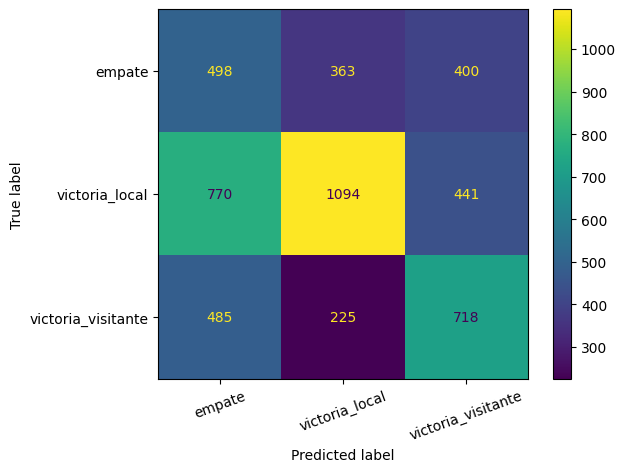

In [28]:
tabla_arbol = reportar_modelo(tuner_arbol, 'Árbol de decisión')

**Efecto del balanceo de clases.** Para aislar el efecto de `class_weight`, se toma el árbol sintonizado (con `set_params(**tuner_arbol.best_params_)`, como en el cuaderno 16) y se evalúa con y sin balanceo, dejando fijos los demás hiperparámetros, con `cross_val_score` y los mismos pliegues de `cv` (cuaderno 12).

In [29]:
# árbol con los hiperparámetros sintonizados; se usa aquí y en las curvas de entrenamiento y validación
arbol_sintonizado = Pipeline(steps=[
    ('preprocessor', preprocessor_arboles),
    ('model', DecisionTreeClassifier(random_state=SEED))
    ])

comparacion_peso = {}
for peso in ['balanced', None]:
    arbol_sintonizado.set_params(**tuner_arbol.best_params_)
    arbol_sintonizado.set_params(model__class_weight=peso)
    fila = {}
    for metrica in SCORING:
        signo = -1 if 'neg_' in metrica else 1
        scores = cross_val_score(arbol_sintonizado, X_train, y_train, cv=cv, scoring=SCORING[metrica], n_jobs=-1)
        fila[metrica.replace('neg_', '')] = signo * scores.mean()
    comparacion_peso[str(peso)] = fila

pd.DataFrame(comparacion_peso).T.round(4)

,f1_macro,accuracy,log_loss
balanced,0.4543,0.4669,1.0249
None,0.4042,0.5180,0.9959


**Curvas de entrenamiento y validación.** Para comprobar que el árbol sintonizado no quedó sobreajustado ni subajustado se repite el análisis de los cuadernos 11 y 12: se recorre cada hiperparámetro alrededor del valor elegido, dejando los demás en sus valores sintonizados; en cada valor se entrena el árbol con `X_train` (desempeño de entrenamiento) y se valida con `cross_val_score` sobre los mismos pliegues de `cv`. Al aumentar la complejidad, el desempeño de entrenamiento siempre mejora, mientras que el de validación mejora hasta un punto y después empeora. El valor sintonizado (cuadrado negro) debería quedar en esa zona.

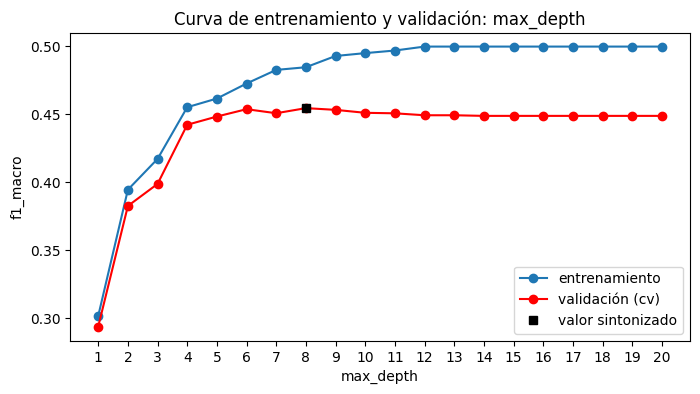

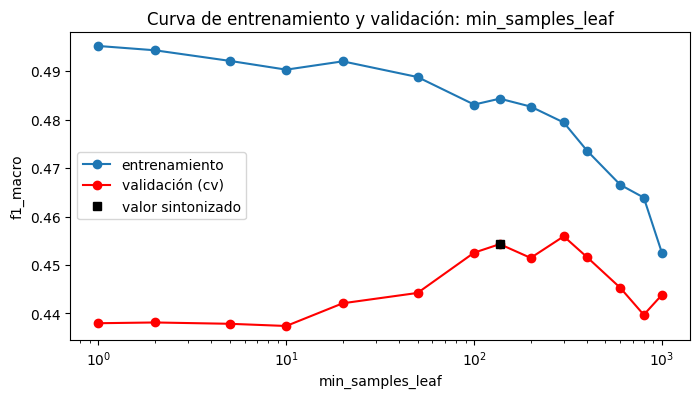

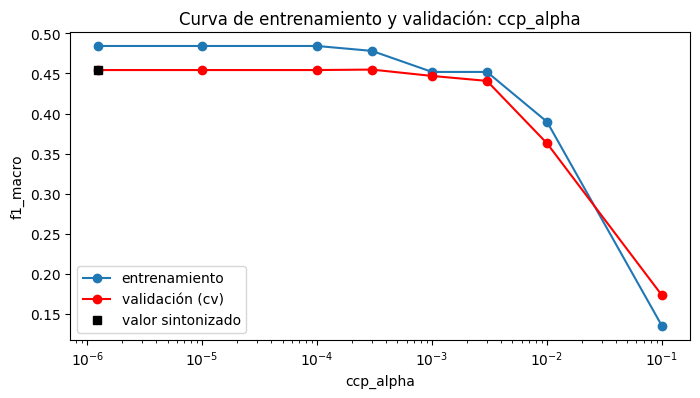

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score


def curva(parametro, valores, escala_log=False):
    # f1_macro de entrenamiento y de validación al variar un hiperparámetro, con los demás sintonizados
    scores_train = []
    scores_val = []
    for valor in valores:
        arbol_sintonizado.set_params(**tuner_arbol.best_params_)
        cambio = {'model__' + parametro: valor}
        arbol_sintonizado.set_params(**cambio)
        arbol_sintonizado.fit(X_train, y_train)
        scores_train.append(f1_score(y_train, arbol_sintonizado.predict(X_train), average='macro'))
        scores_val.append(cross_val_score(arbol_sintonizado, X_train, y_train, cv=cv,
                                          scoring=REFIT, n_jobs=-1).mean())

    sintonizado = tuner_arbol.best_params_['model__' + parametro]
    plt.figure(figsize=(8, 4))
    plt.plot(valores, scores_train, '-o', label='entrenamiento')
    plt.plot(valores, scores_val, '-or', label='validación (cv)')
    plt.plot(sintonizado, scores_val[valores.index(sintonizado)], 'ks', label='valor sintonizado')
    if escala_log:
        plt.xscale('log')
    else:
        plt.xticks(valores)
    plt.xlabel(parametro)
    plt.ylabel('f1_macro')
    plt.title(f'Curva de entrenamiento y validación: {parametro}')
    plt.legend()
    plt.show()


curva('max_depth', list(range(1, 21)))
curva('min_samples_leaf',
      sorted([1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 600, 800, 1000]
             + [tuner_arbol.best_params_['model__min_samples_leaf']]),
      escala_log=True)
curva('ccp_alpha',
      sorted([1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1] + [tuner_arbol.best_params_['model__ccp_alpha']]),
      escala_log=True)

**Lectura de las métricas y de la sintonización.**

- **Sin sobreajuste ni subajuste.** Validación, entrenamiento y prueba están a menos de 0,035 entre sí en las tres métricas (`f1_macro` de 0,454, 0,484 y 0,453), y la prueba coincide con la validación, así que el árbol generaliza lo que aprende. La regularización la hace la pre-poda: profundidad máxima 8 y hojas de al menos 137 partidos. El `ccp_alpha` elegido (≈ 1,2·10⁻⁶) es prácticamente cero, así que la poda por costo-complejidad no tiene nada que corregir.
- **Las curvas confirman que los valores elegidos están en la zona correcta.** En `max_depth`, con 4 niveles o menos el árbol está subajustado (las dos curvas son bajas); la validación es máxima entre 6 y 9 niveles, y a partir de 10 el entrenamiento sigue subiendo mientras la validación baja un poco, que es el comienzo del sobreajuste. En `min_samples_leaf`, con hojas de 50 partidos o menos el árbol se sobreajusta (entrenamiento ≈ 0,49 y validación ≈ 0,44), con 600 o más se subajusta (bajan las dos curvas), y el valor elegido queda en la zona alta, entre 100 y 400 partidos, donde las diferencias (≤ 0,002) son menores que la variación entre pliegues (≈ 0,007). En `ccp_alpha`, la curva es plana hasta 3·10⁻⁴ y cae a partir de 10⁻³ porque la poda empieza a quitar ramas útiles: el valor elegido está en la zona plana, que equivale a no podar.
- **El hiperparámetro que decide vuelve a ser `class_weight`.** Con los demás hiperparámetros fijos, quitar el balanceo sube la exactitud de validación de 0,467 a 0,518 y mejora el `log_loss` de 1,025 a 0,996, pero el `f1_macro` cae de 0,454 a 0,404, porque el árbol deja de predecir empates. Con `'balanced'` el empate alcanza un recall de 0,39 en prueba (0,27 en la regresión logística), a cambio de acertar menos victorias locales (recall de 0,47).
- **Frente a las líneas base y a la regresión logística.** El `log_loss` de prueba (1,025) es mejor que el de asignar a todos los partidos las frecuencias históricas de cada resultado (≈ 1,064), pero la exactitud (0,463) apenas iguala la de predecir siempre victoria local (0,462): el balanceo sacrifica aciertos en la clase mayoritaria para detectar empates. Frente a la regresión logística, el árbol queda por debajo en las tres métricas de prueba: `f1_macro` de 0,453 frente a 0,461, exactitud de 0,463 frente a 0,490 y `log_loss` de 1,025 frente a 1,006.

El árbol repite el dilema de la regresión logística: si lo que se quiere es **clasificar** también los empates, conviene `'balanced'`, que es lo que elige la métrica acordada (`f1_macro`); si lo que se quieren son **probabilidades** para compararlas con el mercado de apuestas, conviene `class_weight=None`, que da un mejor `log_loss`. Además, un solo árbol aproxima con escalones una relación que es gradual (a más diferencia de calidad entre los planteles, más probabilidad de ganar), y la regresión logística la capta mejor con una curva suave. A cambio, el árbol ofrece reglas *si-entonces* que se pueden mostrar a un cliente tal cual (B.2.5). Se retoma en la comparación de la Parte C.

### B.2.4 Importancia relativa de las características

El árbol no tiene coeficientes. Su tabla propia es `feature_importances_`, con los nombres de `get_feature_names_out()` del preprocesador, como en los cuadernos 21 a 23. Mide cuánto reduce la impureza cada característica en los cortes donde se usa, ponderado por el número de partidos que pasan por esos nodos, y suma 1 entre todas las características. A diferencia de los pesos de la regresión logística, **no tiene signo**: dice cuánto usa el árbol una variable, no si aumenta o disminuye la probabilidad de un resultado.

In [31]:
def bloque(nombre):
    # bloque de variables de la Entrega 1 al que pertenece cada característica
    if 'rating_medio' in nombre or 'potencial_medio' in nombre:
        return 'calidad de plantilla'
    if 'league_id' in nombre:
        return 'liga'
    if 'stage' in nombre:
        return 'jornada'
    return 'perfil táctico'


modelo_arbol = tuner_arbol.best_estimator_
importances = modelo_arbol.named_steps['model'].feature_importances_
features = modelo_arbol.named_steps['preprocessor'].get_feature_names_out()

importancias_arbol = pd.DataFrame({'Feature': features, 'Importance': importances})
importancias_arbol['Bloque'] = importancias_arbol['Feature'].map(bloque)

print(f"Características con importancia mayor que cero: "
      f"{(importancias_arbol['Importance'] > 0).sum()} de {len(importancias_arbol)}")
importancias_arbol[importancias_arbol['Importance'] > 0].sort_values('Importance', ascending=False)

Características con importancia mayor que cero: 21 de 40


,Feature,Importance,Bloque
20,num__visitante_potencial_medio,0.309440,calidad de plantilla
18,num__local_potencial_medio,0.242088,calidad de plantilla
19,num__visitante_rating_medio,0.186555,calidad de plantilla
17,num__local_rating_medio,0.164343,calidad de plantilla
1,num__local_buildUpPlaySpeed,0.010282,perfil táctico
2,num__local_buildUpPlayPassing,0.009055,perfil táctico
0,num__stage,0.007214,jornada
6,num__local_defencePressure,0.006938,perfil táctico
9,num__visitante_buildUpPlaySpeed,0.006691,perfil táctico
10,num__visitante_buildUpPlayPassing,0.006666,perfil táctico


In [32]:
# importancia agregada por bloque de variables (incluye las características con importancia cero)
importancias_arbol.groupby('Bloque')['Importance'].sum().sort_values(ascending=False)

Bloque
calidad de plantilla    0.902427
perfil táctico          0.085756
jornada                 0.007214
liga                    0.004603
Name: Importance, dtype: float64

**Lectura de las importancias.**

- **La calidad de las alineaciones domina, igual que en la regresión logística.** Las cuatro variables de rating y potencial medio concentran el **90 %** de la reducción de impureza: `visitante_potencial_medio` (0,31), `local_potencial_medio` (0,24), `visitante_rating_medio` (0,19) y `local_rating_medio` (0,16).
- **El potencial pesa más que el rating.** Es lo contrario de la regresión logística, donde el rating dominaba y el potencial solo hacía un ajuste fino. El árbol no busca relaciones lineales sino umbrales, y los cortes sobre el potencial son los que mejor separan a los planteles de élite (B.2.5). Como rating y potencial están muy correlacionados, los dos modelos cuentan en el fondo la misma historia: gana el que tiene mejor alineación.
- **El perfil táctico aporta poco y de forma dispersa.** 15 de sus 24 características aparecen en algún corte, pero juntas suman el 8,6 % de la importancia y ninguna supera 0,011. Son cortes de las ramas profundas, que afectan a pocos partidos.
- **La liga casi no se usa.** De sus 11 columnas solo aparece una, la de Francia (`league_id_4769`), con el 0,5 % de la importancia. Es la misma liga que en la regresión logística más empuja hacia el empate. La jornada (`stage`) aporta el 0,7 %.
- **El árbol selecciona variables por sí solo.** Usa 21 de las 40 características; las otras 19, incluidas todas las ordinales y las de estilo táctico codificadas con one-hot, tienen importancia 0.

### B.2.5 Reglas del árbol

Al ser un modelo de caja blanca, el árbol se puede dibujar con `plot_tree`, igual que en los cuadernos 19 a 21. Se muestran sus tres primeros niveles, que contienen los cortes que afectan a más partidos. En cada nodo, `samples` es el número de partidos de entrenamiento que llegan a él y `value` es el número de partidos de cada resultado **ponderado por `class_weight`**, en el orden empate, victoria local y victoria visitante; `class` es el resultado con más peso y el color indica qué tan dominante es.

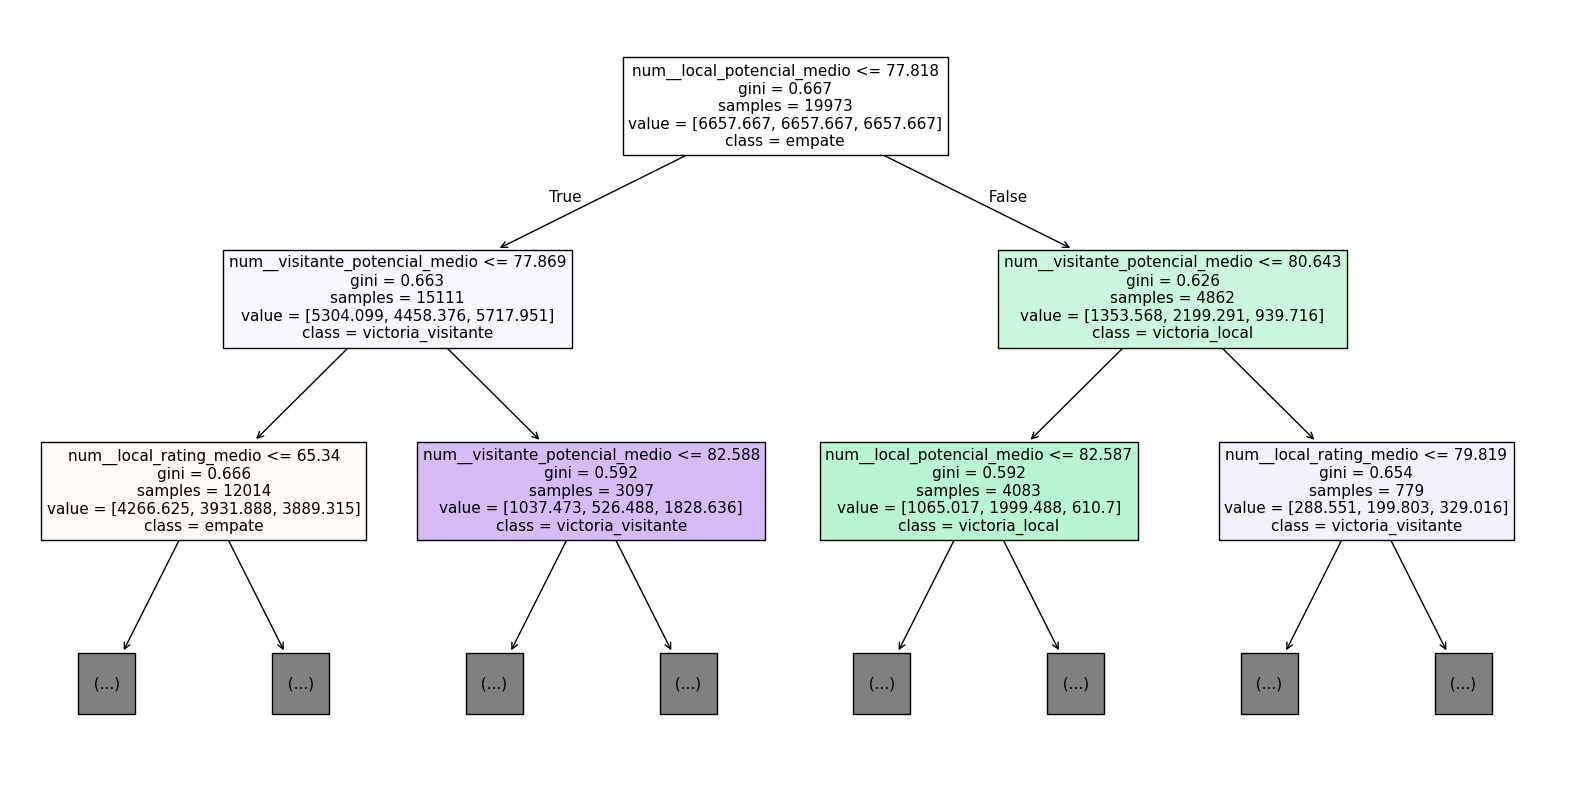

In [33]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    modelo_arbol.named_steps['model'],
    max_depth=2,
    filled=True,
    feature_names=features,
    class_names=modelo_arbol.named_steps['model'].classes_,
    fontsize=11
    )
plt.show();

**Lectura de las reglas.** Los tres primeros niveles solo preguntan por la calidad de las alineaciones, sobre todo por el potencial medio. Las proporciones que siguen se obtienen dividiendo cada `value` entre la suma del nodo:

- **La primera pregunta separa a los locales de élite.** ¿El local tiene un potencial medio mayor a 77,8? Así ocurre en 4.862 de los 19.973 partidos de entrenamiento (24,3 %). En ese grupo la proporción ponderada de victoria local es 0,49, y sube a 0,54 si el visitante no supera 80,6 de potencial (4.083 partidos). Si el visitante también es de élite (779 partidos), el favorito deja de ser el local: la victoria visitante pasa a 0,40.
- **Cuando el local no es de élite, decide el visitante.** En los 15.111 partidos restantes la pregunta es si el visitante supera 77,9 de potencial. Si lo supera (3.097 partidos), la victoria visitante domina (0,54). Si no (12.014 partidos), los dos equipos son de nivel parecido y el nodo queda casi equilibrado (0,35 empate, 0,33 local y 0,32 visitante): es la zona donde el árbol tiende a predecir empate, y su siguiente corte ya usa el rating del local.
- **Los valores están ponderados.** La raíz aparece como `class = empate` solo porque, con `class_weight='balanced'`, los tres resultados pesan lo mismo (6.657,7 cada uno) y, en caso de empate, gana la primera clase en orden alfabético. Por la misma razón, las proporciones de los nodos no son frecuencias reales: el balanceo aumenta el peso del empate y de la victoria visitante.

En resumen, **el árbol compara la calidad de los dos planteles y solo se inclina por el empate cuando son parecidos**, una regla que se le puede explicar a un cliente de la consultora sin hacer ningún cálculo.

### B.2.6 Importancia por permutación

Es la medida común a los tres modelos (A.7): cuánto cae el `f1_macro` en el conjunto de prueba al desordenar cada una de las 30 variables originales. Complementa `feature_importances_` por dos razones: agrupa en una sola cifra las columnas one-hot de una misma variable, y mide el efecto real sobre la métrica de sintonización con datos que el árbol no vio, mientras que la reducción de impureza se calcula con los datos de entrenamiento.

In [34]:
importancia_arbol = importancia_permutacion(tuner_arbol, 'Árbol de decisión')
importancia_arbol.round(4)

,importancia_media,desviacion
Árbol de decisión,,
local_rating_medio,0.0419,0.0058
visitante_rating_medio,0.0417,0.0038
local_potencial_medio,0.0371,0.0047
visitante_potencial_medio,0.0310,0.0027
league_id,0.0017,0.0011
visitante_buildUpPlaySpeed,0.0011,0.0007
local_defenceTeamWidth,0.0008,0.0006
local_chanceCreationCrossing,0.0008,0.0009
stage,0.0005,0.0007


**Lectura de la importancia por permutación.** Confirma las importancias con datos que el árbol no vio: las cuatro variables de calidad de plantilla son las únicas con un efecto claro (desordenarlas hace caer el `f1_macro` entre 0,031 y 0,042), y todas las demás quedan por debajo de 0,002. `league_id` aparece quinta con 0,0017, por el único corte que hace sobre la liga francesa, y las variables tácticas quedan en torno a cero, dentro de su propia desviación, así que sus cortes en las ramas profundas son ruido.

Frente a la regresión logística (B.1.5) hay una diferencia: el árbol reparte la importancia de forma pareja entre las cuatro variables de plantilla, mientras que la logística dependía sobre todo de los dos ratings (0,117 y 0,080). La caída máxima también es menor en el árbol (0,042 frente a 0,117). Una explicación es que el árbol usa a la vez el rating y el potencial de cada equipo, que están muy correlacionados, así que al desordenar uno todavía puede apoyarse en el otro. En la práctica, el árbol también es un modelo de **calidad de plantilla local contra calidad de plantilla visitante**, casi sin ajuste por liga.

### B.2.7 Probabilidades estimadas

En un árbol, la probabilidad de cada resultado es la proporción de partidos de entrenamiento de cada clase en la hoja donde cae el partido, ponderada por `class_weight`. Por eso el árbol solo puede entregar tantas combinaciones distintas de probabilidades como hojas tiene. Igual que en B.1.6, si las probabilidades estuvieran bien calibradas, su promedio en el conjunto de prueba se parecería a la frecuencia real de cada resultado.

In [35]:
probs_arbol = pd.DataFrame(modelo_arbol.predict_proba(X_test),
                           columns=modelo_arbol.named_steps['model'].classes_, index=X_test.index)

print("Combinaciones distintas de probabilidades en el conjunto de prueba:", len(probs_arbol.drop_duplicates()))
print(probs_arbol.head().round(3))
pd.DataFrame({'probabilidad_media_estimada': probs_arbol.mean(),
              'frecuencia_real': y_test.value_counts(normalize=True)}).round(3)

Combinaciones distintas de probabilidades en el conjunto de prueba: 76
       empate  victoria_local  victoria_visitante
17356   0.331           0.216               0.452
4792    0.359           0.181               0.460
8765    0.376           0.380               0.243
11229   0.284           0.425               0.291
21151   0.367           0.332               0.301


,probabilidad_media_estimada,frecuencia_real
empate,0.330,0.253
victoria_local,0.351,0.462
victoria_visitante,0.319,0.286


**Lectura de las probabilidades.** El árbol entrega solo 76 combinaciones distintas de probabilidades, una por hoja: todos los partidos que caen en la misma hoja reciben exactamente la misma probabilidad. Con `class_weight='balanced'` le pasa lo mismo que a la regresión logística: reparte la probabilidad casi en tercios y, en promedio, asigna 0,35 a la victoria local cuando ocurre el 46 % de las veces, y 0,33 al empate cuando ocurre el 25 %. Sus probabilidades sirven para **ordenar** los partidos (cuál tiene más riesgo de terminar en empate), pero no deben leerse como probabilidades reales ni usarse tal cual en el contraste con las cuotas del mercado.

### B.2.8 Resumen del árbol de decisión

| Aspecto | Resultado |
|---|---|
| Preprocesamiento | `preprocessor_arboles`: 21 numéricas sin escalar (`passthrough`), `OrdinalEncoder` (2), `OneHotEncoder` (7) → 40 características |
| Hiperparámetros sintonizados | `max_depth=8`, `min_samples_leaf=137`, `ccp_alpha` ≈ 1,2·10⁻⁶ (sin poda adicional), `class_weight='balanced'` → árbol de 76 hojas |
| `f1_macro` validación / entrenamiento / prueba | 0,454 / 0,484 / 0,453 |
| Exactitud validación / entrenamiento / prueba | 0,467 / 0,491 / 0,463 |
| `log_loss` validación / entrenamiento / prueba | 1,025 / 0,993 / 1,025 |
| Variables que más pesan | potencial y rating medio de las dos alineaciones (90 % de la importancia); la liga casi no se usa |
| Frente a la regresión logística | peor en las tres métricas de prueba, pero detecta más empates (recall 0,39 frente a 0,27) y sus reglas se pueden leer directamente |
| Limitación principal | aproxima con escalones una relación gradual, y el balanceo deja las probabilidades mal calibradas |

## B.3 Modelo de ensamble: random forest

# Parte C — Comparación de los modelos

Las tres tablas guardadas en `resultados` se juntan en una sola. Al compartir partición, validación cruzada, técnica de búsqueda y métrica, las diferencias entre filas se deben al modelo y no al protocolo.

In [24]:
if resultados:
    comparacion = pd.concat(resultados, names=['modelo', 'metrica']).unstack('metrica')
    comparacion = comparacion.swaplevel(axis=1).sort_index(axis=1)
    display(comparacion.round(4))
else:
    print("Todavía no hay modelos reportados con reportar_modelo().")

metrica                  accuracy                         f1_macro          \
                    entrenamiento  prueba validacion entrenamiento  prueba   
modelo                                                                       
Regresión logística        0.4949  0.4904     0.4895        0.4669  0.4613   

metrica                             log_loss                     
                    validacion entrenamiento  prueba validacion  
modelo                                                           
Regresión logística     0.4614        1.0043  1.0058     1.0089